In [2]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# 1. Load dataset
X, y = load_iris(return_X_y=True)

# 2. Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Pipeline
clf = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5, metric="euclidean")),
])

# 4. Fit + evaluate
clf.fit(X_train, y_train)
print(f"Accuracy: {clf.score(X_test, y_test):.4f}")

Accuracy: 0.9333


Visualizations

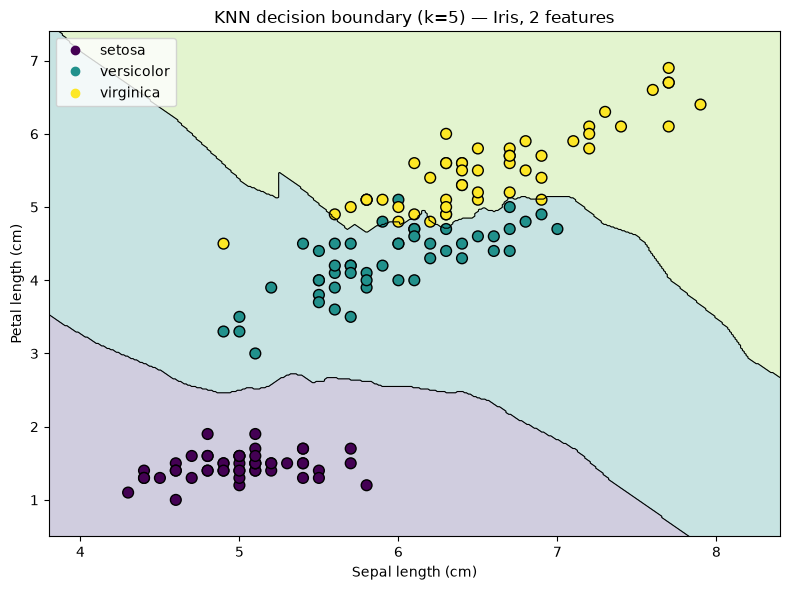

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

X, y = load_iris(return_X_y=True)
# Keep only features 0 and 2 (sepal length, petal length) — most separable pair
X2 = X[:, [0, 2]]

clf = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5)),
]).fit(X2, y)

# Dense grid to evaluate the classifier everywhere
xx, yy = np.meshgrid(
    np.linspace(X2[:, 0].min() - 0.5, X2[:, 0].max() + 0.5, 400),
    np.linspace(X2[:, 1].min() - 0.5, X2[:, 1].max() + 0.5, 400),
)
grid = np.c_[xx.ravel(), yy.ravel()]
Z = clf.predict(grid).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(8, 6))
ax.contourf(xx, yy, Z, alpha=0.25, cmap="viridis", levels=[-0.5, 0.5, 1.5, 2.5])
ax.contour(xx, yy, Z, colors="k", linewidths=0.8, levels=[0.5, 1.5])
scatter = ax.scatter(X2[:, 0], X2[:, 1], c=y, cmap="viridis",
                     edgecolor="k", s=60)
ax.set_xlabel("Sepal length (cm)")
ax.set_ylabel("Petal length (cm)")
ax.set_title("KNN decision boundary (k=5) — Iris, 2 features")
handles, _ = scatter.legend_elements()
ax.legend(handles, ["setosa", "versicolor", "virginica"], loc="upper left")
plt.tight_layout()
plt.savefig("knn_boundary.png", dpi=120)
plt.show()

Best k = 3, test acc = 0.9825


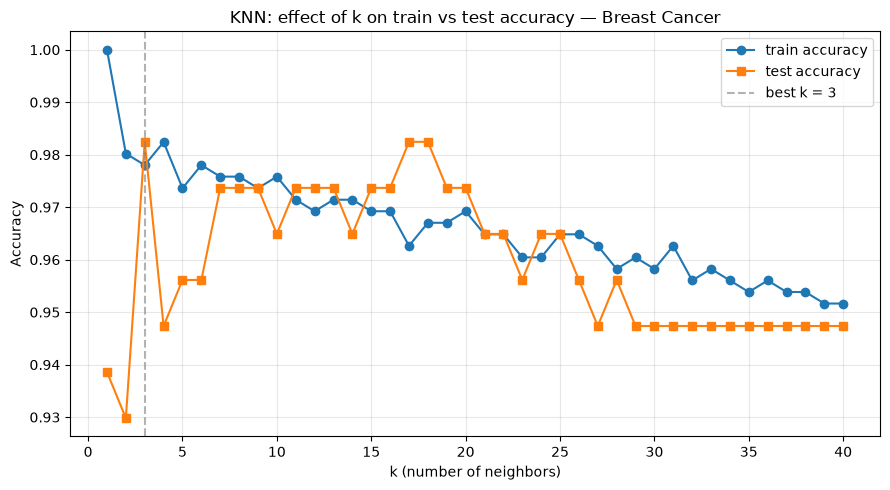

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

ks = list(range(1, 41))
train_acc, test_acc = [], []

for k in ks:
    clf = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k)),
    ]).fit(X_train, y_train)
    train_acc.append(clf.score(X_train, y_train))
    test_acc.append(clf.score(X_test, y_test))

best_k = ks[int(np.argmax(test_acc))]
print(f"Best k = {best_k}, test acc = {max(test_acc):.4f}")

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(ks, train_acc, "o-", label="train accuracy", color="tab:blue")
ax.plot(ks, test_acc, "s-", label="test accuracy", color="tab:orange")
ax.axvline(best_k, ls="--", color="grey", alpha=0.6,
           label=f"best k = {best_k}")
ax.set_xlabel("k (number of neighbors)")
ax.set_ylabel("Accuracy")
ax.set_title("KNN: effect of k on train vs test accuracy — Breast Cancer")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig("knn_k_sweep.png", dpi=120)
plt.show()